# Tugas Besar 2 IF3170 Inteligensi Artifisial

Notebook pipeline data dan pemodelan untuk kompetisi Kaggle `T2-IF3170-2026-2027`.

---

## Group 30

- Ega Luthfi Rais (13524115)
- Faris Wirakusuma Triawan (13524130)
- Ahmad Fauzan Putra (13524141)
- Jonathan Harijadi (13524144)
- Muhammad Hartawan Haidir (13524147)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

Tugas Besar 2 IF3170 Inteligensi Artifisial 2026/2027: Supervised Learning
from scratch untuk kompetisi Kaggle `T2-IF3170-2026-2027` (metrik macro F1).

## Overview

Proyek ini membangun pipeline machine learning untuk memprediksi pembatalan pemesanan penginapan (`is_canceled`) pada kompetisi Kaggle `T2-IF3170-2026-2027`. Lima algoritma klasifikasi—K-Nearest Neighbors (KNN), Decision Tree Learning (ID3), Logistic Regression (L1, L2, Elastic Net), Support Vector Machine (Linear, Polynomial, Gaussian), dan Naive Bayes—diimplementasikan menggunakan NumPy lalu dibandingkan dengan implementasi `scikit-learn`.

## Aim

1. Membangun pipeline preprocessing data.
2. Mengimplementasikan dan memvalidasi kelima algoritma klasifikasi.
3. Membandingkan performa model terhadap versi `scikit-learn`.
4. Memverifikasi save/load model dan menghasilkan submisi Kaggle yang reproducible.

## Metric

Metrik evaluasi utama adalah **Macro F1-score**, yaitu rata-rata F1-score pada kelas `0` dan kelas `1`. Metrik ini dipakai karena target mengalami class imbalance (32,77% positif), sehingga kedua kelas diberi bobot yang sama.

## Dataset

Dataset terdiri dari `train.csv` (27.373 baris, 19 kolom: `id`, 14 fitur numerik, 3 fitur kategorikal, target biner `is_canceled`) dan `test.csv` (6.844 baris, 18 kolom tanpa target). Dari EDA (`docs/eda-summary.md`), ada 8 kolom dengan *informative missingness* (2,96%–11,09%), beberapa invalid values (`num_adults == 0`, total malam `0`, `nightly_rate_idr == 0`), 66 duplicate rows di train, serta distribusi train dan test yang identik.

## Approach

1. Stratified train/validation split (80/20, `seed=42`) sebelum preprocessing.
2. Preprocessing via `DataPreprocessor` (`src/data/preprocessing.py`): cleaning invalid values, drop duplicates khusus train, feature engineering + missingness flags, outlier clipping (quantile 1%–99%), median/mode imputation, one-hot encoding, StandardScaler untuk fitur numerik kontinu, serta feature selection (variance threshold + top-38 mutual information).
3. Train dan validasi 5 model *from scratch*, bandingkan dengan versi `scikit-learn`, cek save/load, lalu refit model terbaik pada full train untuk Kaggle submission.

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [1]:
# %pip install -q numpy pandas scikit-learn matplotlib seaborn joblib

## Import Libraries

Every import of the notebook is kept in this cell.

In [2]:
import hashlib
import json
import os
import random
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "models" / "decision_tree.py").exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data.preprocessing import (
    CATEGORICAL_COLS,
    ID_COL,
    MISSING_FLAG_COLS,
    NUMERIC_COLS,
    TARGET,
    DataPreprocessor,
)
from src.models import DecisionTree, KNN, LogisticRegression, NaiveBayes, SVM

model_registry = {}

## Settings

Paths and shared constants are kept in this class.

In [3]:
class Settings:
    SEED = int(os.environ.get("SEED", 42))
    DATA_DIR = ROOT / "data" / "raw"
    PREP_DIR = ROOT / "output" / "prepared"
    OUTPUT_DIR = ROOT / "output"
    TARGET = "is_canceled"
    ID_COL = "id"

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## Seed Everything

A fixed seed keeps the results reproducible.

In [4]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [5]:
RAW_AVAILABLE = (CFG.DATA_DIR / "train.csv").exists() and (CFG.DATA_DIR / "test.csv").exists()

if RAW_AVAILABLE:
    train_df = pd.read_csv(CFG.DATA_DIR / "train.csv", dtype={CFG.ID_COL: str})
    test_df = pd.read_csv(CFG.DATA_DIR / "test.csv", dtype={CFG.ID_COL: str})
    print(f"Train: {train_df.shape}  Test: {test_df.shape}")
else:
    _tr = np.load(CFG.PREP_DIR / "train.npz")
    _va = np.load(CFG.PREP_DIR / "val.npz")
    _te = np.load(CFG.PREP_DIR / "test.npz", allow_pickle=True)
    print("data/raw/ tidak ditemukan; menggunakan split siap pakai di output/prepared/.")
    print(f"Prepared -> train: {_tr['X'].shape}  val: {_va['X'].shape}  test: {_te['X'].shape}")

data/raw/ tidak ditemukan; menggunakan split siap pakai di output/prepared/.
Prepared -> train: (21898, 38)  val: (5475, 38)  test: (6844, 38)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [6]:
if RAW_AVAILABLE:
    print(f"Train shape: {train_df.shape} | Test shape: {test_df.shape}")
    print(f"Target positive rate ({CFG.TARGET}=1): {train_df[CFG.TARGET].mean():.4f}")
    display(pd.DataFrame({"dtype": train_df.dtypes, "n_unique": train_df.nunique()}))
    display(train_df.head())
else:
    _feat_names = json.loads((CFG.PREP_DIR / "feature_names.json").read_text())
    print(f"Prepared features ({len(_feat_names)}): {_feat_names[:10]} ...")
    print(f"Target positive rate -> train: {_tr['y'].mean():.4f} | val: {_va['y'].mean():.4f}")

Prepared features (38): ['weekend_nights', 'weekday_nights', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests'] ...
Target positive rate -> train: 0.3277 | val: 0.3277


## Explore Data

This part covers distributions and relationships between attributes.

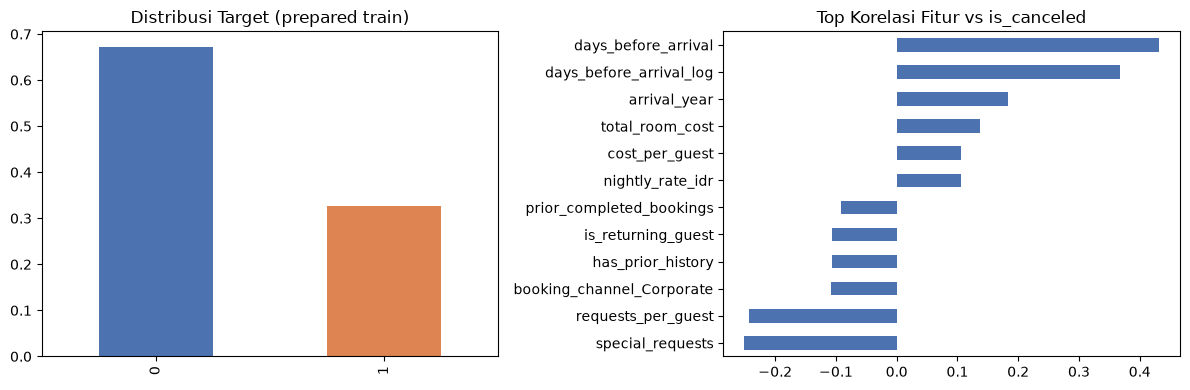

In [7]:
if RAW_AVAILABLE:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    train_df[CFG.TARGET].value_counts(normalize=True).sort_index().plot.bar(
        ax=axes[0], color=["#4C72B0", "#DD8452"]
    )
    axes[0].set_title("Distribusi Target (is_canceled)")
    axes[0].set_xlabel(CFG.TARGET)
    axes[0].set_ylabel("Proporsi")

    corr = train_df[NUMERIC_COLS + [CFG.TARGET]].corr()[CFG.TARGET].drop(CFG.TARGET).sort_values()
    corr.plot.barh(ax=axes[1], color="#4C72B0")
    axes[1].set_title("Korelasi Fitur Numerik vs is_canceled")
    axes[1].axvline(0, color="black", linewidth=0.8)

    train_df.groupby("booking_channel")[CFG.TARGET].mean().sort_values().plot.barh(
        ax=axes[2], color="#55A868"
    )
    axes[2].set_title("Cancellation Rate per booking_channel")
    axes[2].set_xlabel("Cancellation rate")

    plt.tight_layout()
    plt.show()
else:
    _feat_names = json.loads((CFG.PREP_DIR / "feature_names.json").read_text())
    corrs = pd.Series(
        [np.corrcoef(_tr["X"][:, j], _tr["y"])[0, 1] for j in range(_tr["X"].shape[1])],
        index=_feat_names,
    ).sort_values()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    pd.Series(_tr["y"]).value_counts(normalize=True).sort_index().plot.bar(
        ax=axes[0], color=["#4C72B0", "#DD8452"]
    )
    axes[0].set_title("Distribusi Target (prepared train)")
    pd.concat([corrs.head(6), corrs.tail(6)]).plot.barh(ax=axes[1], color="#4C72B0")
    axes[1].set_title("Top Korelasi Fitur vs is_canceled")
    plt.tight_layout()
    plt.show()

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [8]:
if RAW_AVAILABLE:
    miss_tbl = pd.DataFrame({
        "train_missing_%": (train_df.drop(columns=[CFG.TARGET]).isna().mean() * 100).round(2),
        "test_missing_%": (test_df.isna().mean() * 100).round(2),
    })
    display(miss_tbl[miss_tbl["train_missing_%"] > 0].sort_values("train_missing_%", ascending=False))

    feat_cols = [c for c in train_df.columns if c not in (CFG.ID_COL, CFG.TARGET)]
    print("Duplikat fitur (train)         :", int(train_df.duplicated(subset=feat_cols).sum()))
    print("num_adults == 0                :", int((train_df["num_adults"] == 0).sum()))
    print("weekend + weekday nights == 0  :", int(((train_df["weekend_nights"] + train_df["weekday_nights"]) == 0).sum()))
    print("nightly_rate_idr == 0          :", int((train_df["nightly_rate_idr"] == 0).sum()))
else:
    print(
        "Prepared NaN count -> train:", int(np.isnan(_tr["X"]).sum()),
        "| val:", int(np.isnan(_va["X"]).sum()),
        "| test:", int(np.isnan(_te["X"]).sum()),
    )
    print(
        "Temuan kualitas data mentah (docs/eda-summary.md): 8 kolom missing (2.96%-11.09%), "
        "66 duplikat fitur, 106 baris num_adults=0, 64 baris 0 malam, 413 baris nightly_rate_idr=0."
    )

Prepared NaN count -> train: 0 | val: 0 | test: 0
Temuan kualitas data mentah (docs/eda-summary.md): 8 kolom missing (2.96%-11.09%), 66 duplikat fitur, 106 baris num_adults=0, 64 baris 0 malam, 413 baris nightly_rate_idr=0.


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [9]:
prep = DataPreprocessor(seed=CFG.SEED, select_k=38)

if RAW_AVAILABLE:
    train_set, val_set = prep.split(train_df)
    print(f"train_set: {train_set.shape} (pos={train_set[CFG.TARGET].mean():.4f})")
    print(f"val_set  : {val_set.shape} (pos={val_set[CFG.TARGET].mean():.4f})")
else:
    print(
        f"Prepared split (stratified 80/20, seed={CFG.SEED}) -> "
        f"train: {_tr['X'].shape} (pos={_tr['y'].mean():.4f}) | "
        f"val: {_va['X'].shape} (pos={_va['y'].mean():.4f})"
    )

Prepared split (stratified 80/20, seed=42) -> train: (21898, 38) (pos=0.3277) | val: (5475, 38) (pos=0.3277)


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [10]:
print(f"Fitur numerik ({len(NUMERIC_COLS)}):", NUMERIC_COLS)
print(f"Fitur kategorikal ({len(CATEGORICAL_COLS)}):", CATEGORICAL_COLS)
print(f"Kolom non-fitur yang dipisahkan: {[CFG.ID_COL, CFG.TARGET]}")

Fitur numerik (14): ['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']
Fitur kategorikal (3): ['meal_package', 'room_category', 'booking_channel']
Kolom non-fitur yang dipisahkan: ['id', 'is_canceled']


## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [11]:
print("Kolom dengan informative missingness (ditambah flag *_is_missing):", MISSING_FLAG_COLS)
print("Imputation (fit di train saja): median untuk numeric, mode untuk categorical.")
if RAW_AVAILABLE:
    display(train_set[MISSING_FLAG_COLS].isna().mean().mul(100).round(2).rename("train_missing_%").to_frame())

Kolom dengan informative missingness (ditambah flag *_is_missing): ['num_adults', 'num_children', 'meal_package', 'room_category', 'days_before_arrival', 'needs_parking', 'nightly_rate_idr', 'special_requests']
Imputation (fit di train saja): median untuk numeric, mode untuk categorical.


### Duplicates

This part covers repeated records.

In [12]:
if RAW_AVAILABLE:
    feat_cols = [c for c in train_set.columns if c not in (CFG.ID_COL, CFG.TARGET)]
    print("Duplicate feature rows di train_set (di-drop saat fit saja):", int(train_set.duplicated(subset=feat_cols).sum()))
else:
    print("Duplicate feature rows (66 baris di dataset penuh) di-drop khusus di training split oleh DataPreprocessor._clean().")

Duplicate feature rows (66 baris di dataset penuh) di-drop khusus di training split oleh DataPreprocessor._clean().


### Outliers

This part covers values far from the rest of the data.

In [13]:
print(f"Outlier clipping: quantile {prep.clip_quantiles} dihitung dari training set untuk kolom numeric kontinu.")
if RAW_AVAILABLE:
    for col in ["nightly_rate_idr", "days_before_arrival", "prior_completed_bookings"]:
        lo, hi = train_set[col].quantile(prep.clip_quantiles).tolist()
        print(f"  {col:<26} -> clip [{lo:.2f}, {hi:.2f}] (raw max={train_set[col].max():.2f})")

Outlier clipping: quantile (0.01, 0.99) dihitung dari training set untuk kolom numeric kontinu.


### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [14]:
if RAW_AVAILABLE:
    cleaned_train = prep._clean(train_set, drop_duplicates=True)
    print(f"Jumlah baris train sebelum/sesudah _clean: {len(train_set)} -> {len(cleaned_train)}")
print("Invalid values (num_adults=0, total_nights=0, nightly_rate_idr=0) diubah ke NaN sebelum imputation.")

Invalid values (num_adults=0, total_nights=0, nightly_rate_idr=0) diubah ke NaN sebelum imputation.


## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

This part covers new attributes derived from existing ones.

In [15]:
if RAW_AVAILABLE:
    eng_train = prep._engineer(cleaned_train)
    derived = [c for c in eng_train.columns if c not in train_set.columns]
    print(f"Engineered features ({len(derived)}):", derived)
else:
    print(
        "Engineered features (DataPreprocessor._engineer): has_children, is_family, arrival_quarter, "
        "is_high_season, days_before_arrival_log, nightly_rate_per_guest, total_room_cost, "
        "cost_per_guest, prior_cancel_ratio, has_prior_history, requests_per_guest, dan 8 flag *_is_missing."
    )

Engineered features (DataPreprocessor._engineer): has_children, is_family, arrival_quarter, is_high_season, days_before_arrival_log, nightly_rate_per_guest, total_room_cost, cost_per_guest, prior_cancel_ratio, has_prior_history, requests_per_guest, dan 8 flag *_is_missing.


### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [16]:
print(
    "StandardScaler diterapkan pada kolom numeric kontinu saja (fit di train); "
    "kolom binary, missing flags, dan one-hot features tidak di-scale."
)

StandardScaler diterapkan pada kolom numeric kontinu saja (fit di train); kolom binary, missing flags, dan one-hot features tidak di-scale.


### Encoding

This part covers the numeric representation of categorical attributes.

In [17]:
print(f"OneHotEncoder(handle_unknown='ignore', min_frequency=0.01) untuk: {CATEGORICAL_COLS}")
if RAW_AVAILABLE:
    for col in CATEGORICAL_COLS:
        print(f"  {col}: {train_set[col].dropna().value_counts().to_dict()}")

OneHotEncoder(handle_unknown='ignore', min_frequency=0.01) untuk: ['meal_package', 'room_category', 'booking_channel']


### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [18]:
print("Feature selection: VarianceThreshold(1e-8) + top-38 Mutual Information (select_k=38).")
print("PCA tersedia sebagai opsi (use_pca=False pada pipeline utama supaya fitur tetap interpretable untuk tree).")
if RAW_AVAILABLE:
    prep_pca = DataPreprocessor(seed=CFG.SEED, select_k=38, use_pca=True, pca_variance=0.95)
    X_pca_tr, _ = prep_pca.fit_transform(train_set)
    print(f"Dimensi -> tanpa PCA: 38 fitur | dengan PCA (95% variance): {X_pca_tr.shape[1]} components")

Feature selection: VarianceThreshold(1e-8) + top-38 Mutual Information (select_k=38).
PCA tersedia sebagai opsi (use_pca=False pada pipeline utama supaya fitur tetap interpretable untuk tree).


## Class Balance

This part covers the proportion of each class in the training data.

In [19]:
_y_bal = train_set[CFG.TARGET].to_numpy() if RAW_AVAILABLE else _tr["y"]
counts = pd.Series(_y_bal).value_counts().sort_index()
display(pd.DataFrame({"count": counts, "share": (counts / len(_y_bal)).round(4)}))
print(
    "Class distribution ~67.2% negatif vs ~32.8% positif. Tidak dilakukan resampling di awal; "
    "class imbalance ditangani lewat macro F1, class_weight, dan decision threshold tuning."
)

,count,share
0,14723,0.6723
1,7175,0.3277


Class distribution ~67.2% negatif vs ~32.8% positif. Tidak dilakukan resampling di awal; class imbalance ditangani lewat macro F1, class_weight, dan decision threshold tuning.


## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [20]:
print(
    "Output akhir berupa numpy.ndarray float64 tanpa NaN untuk semua model. "
    "DecisionTree juga dites langsung pada raw features (numeric + categorical + null) di Section 7."
)

Output akhir berupa numpy.ndarray float64 tanpa NaN untuk semua model. DecisionTree juga dites langsung pada raw features (numeric + categorical + null) di Section 7.


---

# Preparation Pipeline <a name="6"></a>

---

The pipeline combines the preparation steps so they run in one consistent order.

In [21]:
if RAW_AVAILABLE:
    X_train, y_train = prep.fit_transform(train_set)
    X_val = prep.transform(val_set)
    y_val = val_set[CFG.TARGET].to_numpy()
    X_test = prep.transform(test_df)
    test_ids = test_df[CFG.ID_COL].to_numpy()
    feature_names = list(prep.feature_names_out_)
else:
    _tr = np.load(CFG.PREP_DIR / "train.npz")
    _va = np.load(CFG.PREP_DIR / "val.npz")
    _te = np.load(CFG.PREP_DIR / "test.npz", allow_pickle=True)
    X_train, y_train = _tr["X"], _tr["y"]
    X_val, y_val = _va["X"], _va["y"]
    X_test, test_ids = _te["X"], _te["ids"]
    feature_names = json.loads((CFG.PREP_DIR / "feature_names.json").read_text())
    prep = DataPreprocessor.load(CFG.PREP_DIR / "preprocessor.pkl")

print(f"X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test.shape}")
print(f"NaN -> train: {np.isnan(X_train).sum()} | val: {np.isnan(X_val).sum()} | test: {np.isnan(X_test).sum()}")
display(prep.summary().head(12))

X_train: (21898, 38) | X_val: (5475, 38) | X_test: (6844, 38)
NaN -> train: 0 | val: 0 | test: 0


/home/fariswirakusuma/Ngampus/Semester_5/AI/IF3170_G30_AnthropicHire/.venv/lib64/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.5.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/fariswirakusuma/Ngampus/Semester_5/AI/IF3170_G30_AnthropicHire/.venv/lib64/python3.14/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.5.2 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/fariswirakusuma/Ngampus/Semester_5/AI/IF3170_G30_AnthropicHire/.venv/lib64/pyt

,feature,mutual_information
11,days_before_arrival_log,0.104963
2,days_before_arrival,0.102154
9,special_requests,0.039391
3,arrival_year,0.029136
4,arrival_month,0.029019
13,total_room_cost,0.027164
8,nightly_rate_idr,0.027114
15,requests_per_guest,0.026268
29,is_high_season,0.015787
12,nightly_rate_per_guest,0.015569


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

### Catatan implementasi

Kelima classifier (KNN, DTL, Logistic Regression, SVM, Naive Bayes) di `src/models/` diimplementasikan from scratch dengan NumPy; pandas hanya untuk I/O dan penanganan tabel. scikit-learn dipakai untuk preprocessing di `DataPreprocessor` (`src/data/preprocessing.py`) dan sebagai pembanding, bukan untuk model submission.

## K-Nearest Neighbors

This part covers the nearest neighbor classifier and its validation.

In [22]:
import json
from sklearn.metrics import f1_score, classification_report        
from sklearn.neighbors import KNeighborsClassifier
from src.models.knn import KNN

tr, va = np.load(CFG.PREP_DIR / "train.npz"), np.load(CFG.PREP_DIR / "val.npz")
X_train, y_train, X_val, y_val = tr["X"], tr["y"], va["X"], va["y"]

ks = [1, 3, 5, 7, 9, 11, 15, 21, 31, 51]
probe = KNN(k=max(ks), p=2, weights="distance").fit(X_train, y_train)
dists, idx = probe.kneighbors(X_val)                 
labels = y_train[idx]
sweep = {"uniform": [], "distance": []}
for k in ks:
    sweep["uniform"].append(f1_score(y_val, (labels[:, :k].mean(1) >= .5).astype(int), average="macro"))
    w = 1 / (dists[:, :k] + 1e-12)
    sweep["distance"].append(f1_score(y_val, (((w * labels[:, :k]).sum(1) / w.sum(1)) >= .5).astype(int), average="macro"))
best_w = max(sweep, key=lambda s: max(sweep[s]))
best_k = ks[int(np.argmax(sweep[best_w]))]
print("k terbaik:", best_k, "| bobot:", best_w, "| macro F1:", round(max(sweep[best_w]), 4))

# model final + pembanding scikit-learn
knn = KNN(k=best_k, p=2, weights=best_w).fit(X_train, y_train)
pred_knn = knn.predict(X_val)
model_registry["knn"] = knn
print(classification_report(y_val, pred_knn, digits=4))

knn_sk = KNeighborsClassifier(n_neighbors=best_k, weights=best_w, p=2, algorithm="brute").fit(X_train, y_train)
print("macro F1 scratch :", round(f1_score(y_val, pred_knn, average="macro"), 4))
print("macro F1 sklearn :", round(f1_score(y_val, knn_sk.predict(X_val), average="macro"), 4))
print("prediksi sama    :", (pred_knn == knn_sk.predict(X_val)).mean())

k terbaik: 11 | bobot: distance | macro F1: 0.8296


              precision    recall  f1-score   support

           0     0.8826    0.8984    0.8904      3681
           1     0.7836    0.7547    0.7689      1794

    accuracy                         0.8513      5475
   macro avg     0.8331    0.8266    0.8296      5475
weighted avg     0.8501    0.8513    0.8506      5475

macro F1 scratch : 0.8296
macro F1 sklearn : 0.8296


prediksi sama    : 1.0


## Decision Tree Learning

This part covers the ID3 (entropy / information gain) implementation and its validation, including numeric, categorical, and null handling.

In [23]:
dt_model = DecisionTree(max_depth=12, min_samples_leaf=5).fit(X_train, y_train)
dt_val_pred = dt_model.predict(X_val)
model_registry["decision_tree"] = dt_model

print(f"DecisionTree (ID3) val macro F1: {f1_score(y_val, dt_val_pred, average='macro'):.4f}")
print(classification_report(y_val, dt_val_pred, digits=4))

DecisionTree (ID3) val macro F1: 0.8238
              precision    recall  f1-score   support

           0     0.8726    0.9063    0.8891      3681
           1     0.7912    0.7285    0.7586      1794

    accuracy                         0.8480      5475
   macro avg     0.8319    0.8174    0.8238      5475
weighted avg     0.8459    0.8480    0.8463      5475



In [24]:
# Cek penanganan numeric, categorical, dan null secara langsung (tanpa imputation/encoding)
if RAW_AVAILABLE:
    raw_cols = NUMERIC_COLS + CATEGORICAL_COLS
    dt_raw = DecisionTree(max_depth=10, min_samples_leaf=1).fit(
        train_set[raw_cols], train_set[CFG.TARGET].to_numpy()
    )
    raw_pred = dt_raw.predict(val_set[raw_cols])
    print(
        f"DecisionTree (ID3) pada raw data (numeric + categorical + null) -> "
        f"val macro F1: {f1_score(val_set[CFG.TARGET].to_numpy(), raw_pred, average='macro'):.4f}"
    )
else:
    raw_sample = pd.DataFrame({
        "days_before_arrival": [10.0, 220.0, np.nan, 45.0, 380.0, 5.0],
        "special_requests": [2.0, 0.0, 0.0, np.nan, 0.0, 3.0],
        "meal_package": ["Breakfast", "Half Board", "Half Board", None, "Breakfast", "Room Only"],
        "booking_channel": ["Corporate", "Online Travel Agent", "Online Travel Agent", "Offline Agent", "Online Travel Agent", "Complimentary"],
    })
    raw_y = np.array([0, 1, 1, 0, 1, 0])
    dt_raw = DecisionTree(max_depth=4, min_samples_leaf=1).fit(raw_sample, raw_y)
    print(f"Raw numeric + categorical + null check -> train accuracy: {(dt_raw.predict(raw_sample) == raw_y).mean():.4f}")

Raw numeric + categorical + null check -> train accuracy: 1.0000


## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

,regularization,macro_f1,epochs
1,l2,0.751830,1500
2,elasticnet,0.750328,1500
0,l1,0.749646,847


Regularization terbaik: l2
Validation macro F1: 0.7518
Final training loss: 0.471475
              precision    recall  f1-score   support

           0     0.8738    0.7672    0.8170      3681
           1     0.6179    0.7726    0.6866      1794

    accuracy                         0.7689      5475
   macro avg     0.7458    0.7699    0.7518      5475
weighted avg     0.7899    0.7689    0.7743      5475



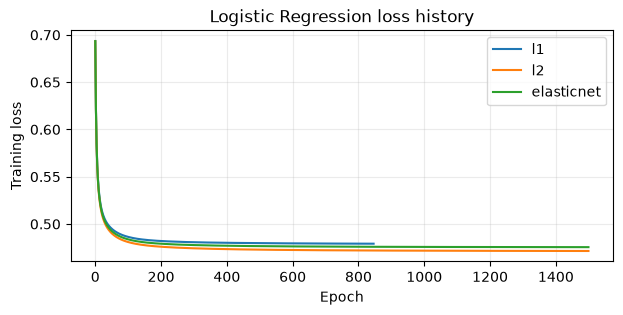

In [25]:
# Logistic Regression from scratch: compare L1, L2, and Elastic Net.
logistic_models = {}
logistic_rows = []

for penalty in ("l1", "l2", "elasticnet"):
    model = LogisticRegression(
        learning_rate=0.15,
        epochs=1500,
        regularization=penalty,
        lambda_=0.001,
        l1_ratio=0.5,
        class_weight="balanced",
        tolerance=1e-8,
        random_state=CFG.SEED,
    )
    model.fit(X_train, y_train)
    pred = model.predict(X_val)
    score = f1_score(y_val, pred, average="macro")
    logistic_models[penalty] = model
    logistic_rows.append({"regularization": penalty, "macro_f1": score, "epochs": model.n_iter_})

logistic_table = pd.DataFrame(logistic_rows).sort_values("macro_f1", ascending=False)
display(logistic_table)
best_penalty = logistic_table.iloc[0]["regularization"]
logreg_model = logistic_models[best_penalty]
pred_logreg = logreg_model.predict(X_val)
model_registry["logistic_regression"] = logreg_model

print("Regularization terbaik:", best_penalty)
print("Validation macro F1:", round(f1_score(y_val, pred_logreg, average="macro"), 4))
print("Final training loss:", round(logreg_model.loss_history_[-1], 6))
print(classification_report(y_val, pred_logreg, digits=4))

plt.figure(figsize=(7, 3))
for name, model in logistic_models.items():
    plt.plot(model.loss_history_, label=name)
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Logistic Regression loss history")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Support Vector Machine

This part covers the linear, polynomial, and Gaussian kernels.

linear     fit=  3.19s  predict=  0.00s  macro F1=0.7594


polynomial fit=  0.48s  predict=  0.15s  macro F1=0.7792


gaussian   fit=  0.84s  predict=  0.22s  macro F1=0.7884


,kernel,fit_s,predict_s,macro_f1
2,gaussian,0.842757,0.223260,0.788380
1,polynomial,0.483981,0.147426,0.779240
0,linear,3.193494,0.000293,0.759379


              precision    recall  f1-score   support

           0     0.8478    0.8900    0.8684      3681
           1     0.7486    0.6722    0.7084      1794

    accuracy                         0.8186      5475
   macro avg     0.7982    0.7811    0.7884      5475
weighted avg     0.8153    0.8186    0.8160      5475



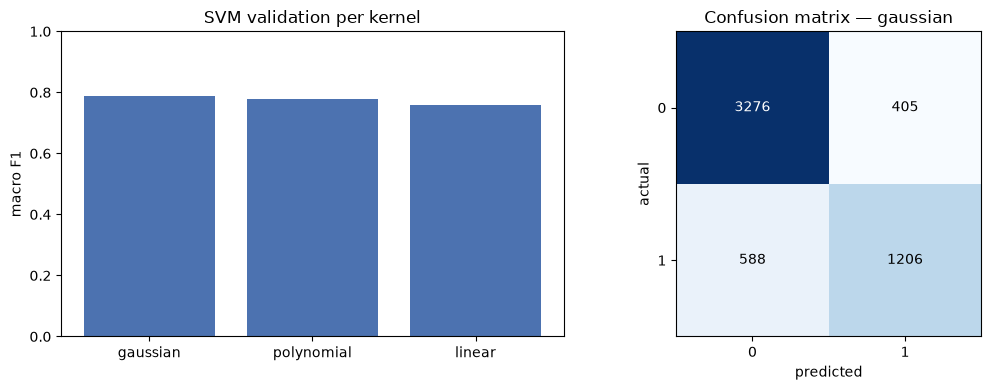

In [26]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, f1_score

# Find the project root so `src.models` is importable from any notebook dir.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "models" / "svm.py").exists())
sys.path.insert(0, str(ROOT))

from src.models.svm import SVM

train = np.load(ROOT / "output" / "prepared" / "train.npz")
val = np.load(ROOT / "output" / "prepared" / "val.npz")
X_train, y_train = train["X"], train["y"]
X_val, y_val = val["X"], val["y"]

# Linear SVM uses all rows; the two kernel SVMs subsample via max_samples.
kernel_params = {
    "linear": dict(kernel="linear", C=1.0, learning_rate=0.002, epochs=50),
    "polynomial": dict(kernel="poly", degree=3, coef0=1.0, gamma=0.1, C=1.0,
                       learning_rate=0.05, epochs=30, max_samples=2000),
    "gaussian": dict(kernel="gaussian", gamma=0.15, C=1.0,
                     learning_rate=0.05, epochs=30, max_samples=2000),
}

svm_rows, svm_models = [], {}
for name, params in kernel_params.items():
    model = SVM(**params)
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred = model.predict(X_val)
    predict_s = time.perf_counter() - t0
    score = f1_score(y_val, pred, average="macro")
    svm_rows.append({"kernel": name, "fit_s": fit_s, "predict_s": predict_s, "macro_f1": score})
    svm_models[name] = model
    print(f"{name:<10} fit={fit_s:6.2f}s  predict={predict_s:6.2f}s  macro F1={score:.4f}")

svm_table = pd.DataFrame(svm_rows).sort_values("macro_f1", ascending=False)
display(svm_table)

best_kernel = svm_table.iloc[0]["kernel"]
best_pred = svm_models[best_kernel].predict(X_val)
print(classification_report(y_val, best_pred, digits=4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(svm_table["kernel"], svm_table["macro_f1"], color="#4C72B0")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("macro F1")
axes[0].set_title("SVM validation per kernel")

labels = np.unique(y_val)
matrix = confusion_matrix(y_val, best_pred)
axes[1].imshow(matrix, cmap="Blues")
axes[1].set_xticks(range(len(labels)), labels)
axes[1].set_yticks(range(len(labels)), labels)
axes[1].set_xlabel("predicted")
axes[1].set_ylabel("actual")
axes[1].set_title(f"Confusion matrix — {best_kernel}")
for i in range(len(labels)):
    for j in range(len(labels)):
        axes[1].text(j, i, matrix[i, j], ha="center", va="center",
                     color="white" if matrix[i, j] > matrix.max() / 2 else "black")

plt.tight_layout()
plt.show()

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [27]:
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from src.models.naive_bayes import NaiveBayes, CategoricalNaiveBayes, backward_elimination

gnb = NaiveBayes().fit(X_train, y_train)
print("Gaussian scratch :", round(f1_score(y_val, gnb.predict(X_val), average="macro"), 4),
      "| sklearn:", round(f1_score(y_val, GaussianNB().fit(X_train, y_train).predict(X_val), average="macro"), 4))
cnb_all = CategoricalNaiveBayes(n_bins=20).fit(X_train, y_train)
print("Kategorikal (semua fitur):", round(f1_score(y_val, cnb_all.predict(X_val), average="macro"), 4))

# seleksi fitur backward (CV di train, ~2-3 menit) + pembanding
feature_names = json.load(open(CFG.PREP_DIR / "feature_names.json"))
cols, history = backward_elimination(X_train, y_train, lambda: CategoricalNaiveBayes(n_bins=20))
print("dibuang:", [feature_names[j] for j, _ in history])

nb = CategoricalNaiveBayes(n_bins=20).fit(X_train[:, cols], y_train)
pred_nb = nb.predict(X_val[:, cols])
print(classification_report(y_val, pred_nb, digits=4))

B_tr, B_va = nb._digitize(X_train[:, cols]), nb._digitize(X_val[:, cols])
nb_sk = CategoricalNB(alpha=1.0, min_categories=nb.n_categories_).fit(B_tr, y_train)
print("macro F1 scratch :", round(f1_score(y_val, pred_nb, average="macro"), 4))
print("macro F1 sklearn :", round(f1_score(y_val, nb_sk.predict(B_va), average="macro"), 4))

Gaussian scratch : 0.4685 | sklearn: 0.4685


Kategorikal (semua fitur): 0.7375


dibuang: ['arrival_quarter', 'cost_per_guest', 'days_before_arrival_log', 'nightly_rate_per_guest', 'special_requests_is_missing', 'total_room_cost', 'weekday_nights', 'booking_channel_Corporate', 'is_high_season', 'meal_package_Breakfast', 'num_children_is_missing']
              precision    recall  f1-score   support

           0     0.8370    0.8481    0.8425      3681
           1     0.6797    0.6611    0.6702      1794

    accuracy                         0.7868      5475
   macro avg     0.7583    0.7546    0.7564      5475
weighted avg     0.7854    0.7868    0.7861      5475

macro F1 scratch : 0.7564
macro F1 sklearn : 0.7564


## Model Evaluation

This part compares the validation results of all models.

,model,macro_f1,accuracy,precision_macro,recall_macro
0,knn,0.829648,0.851324,0.833069,0.826568
1,decision_tree,0.823843,0.848037,0.831888,0.817408
2,svm_gaussian,0.788380,0.818630,0.798215,0.781108
3,naive_bayes_categorical,0.756389,0.786849,0.758327,0.754616
4,logistic_regression,0.751830,0.768950,0.745842,0.769879
5,naive_bayes_gaussian,0.468539,0.480000,0.651910,0.602140


Model terbaik pada validasi: knn (macro F1 = 0.8296)


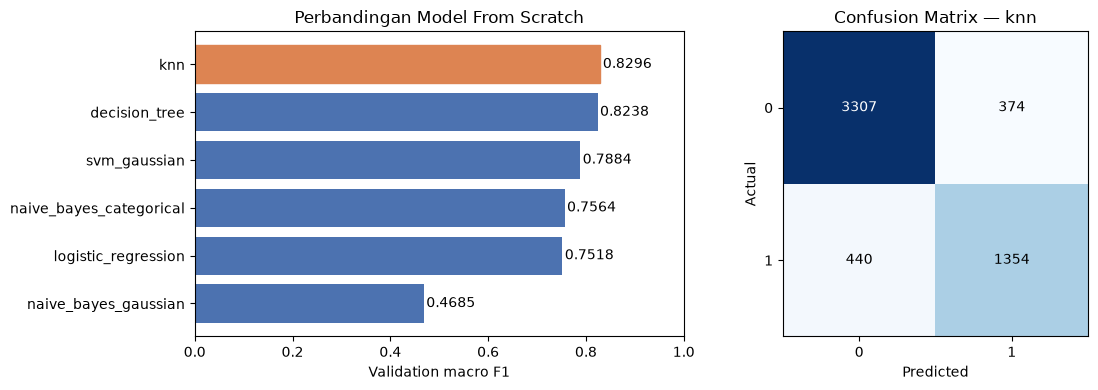

In [28]:
eval_models = {
    "knn": (knn, X_val),
    "decision_tree": (dt_model, X_val),
    "logistic_regression": (logreg_model, X_val),
    f"svm_{best_kernel}": (svm_models[best_kernel], X_val),
    "naive_bayes_gaussian": (gnb, X_val),
}
if "nb" in globals() and "cols" in globals():
    eval_models["naive_bayes_categorical"] = (nb, X_val[:, cols])

eval_rows = []
eval_preds = {}
for name, (model, X_eval) in eval_models.items():
    pred = model.predict(X_eval)
    eval_preds[name] = pred
    eval_rows.append({
        "model": name,
        "macro_f1": f1_score(y_val, pred, average="macro"),
        "accuracy": accuracy_score(y_val, pred),
        "precision_macro": precision_score(y_val, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_val, pred, average="macro", zero_division=0),
    })

eval_table = pd.DataFrame(eval_rows).sort_values("macro_f1", ascending=False).reset_index(drop=True)
display(eval_table)

best_model_name = str(eval_table.iloc[0]["model"])
best_model = eval_models[best_model_name][0]
best_val_pred = eval_preds[best_model_name]
print(f"Model terbaik pada validasi: {best_model_name} (macro F1 = {eval_table.iloc[0]['macro_f1']:.4f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ordered = eval_table.sort_values("macro_f1")
bars = axes[0].barh(ordered["model"], ordered["macro_f1"], color="#4C72B0")
bars[-1].set_color("#DD8452")
for bar, score in zip(bars, ordered["macro_f1"]):
    axes[0].text(score + 0.005, bar.get_y() + bar.get_height() / 2, f"{score:.4f}", va="center")
axes[0].set_xlim(0, 1)
axes[0].set_xlabel("Validation macro F1")
axes[0].set_title("Perbandingan Model From Scratch")

cm = confusion_matrix(y_val, best_val_pred)
axes[1].imshow(cm, cmap="Blues")
axes[1].set_xticks([0, 1], [0, 1])
axes[1].set_yticks([0, 1], [0, 1])
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
axes[1].set_title(f"Confusion Matrix — {best_model_name}")
for i in range(2):
    for j in range(2):
        axes[1].text(
            j, i, cm[i, j], ha="center", va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
        )
plt.tight_layout()
plt.show()

## Improvements (Optional)

This part covers decision threshold tuning on validation probabilities for macro F1.

In [29]:
# Decision threshold tuning pada validation probability DecisionTree untuk macro F1
dt_val_proba = dt_model.predict_proba(X_val)[:, 1]
thresholds = np.linspace(0.25, 0.75, 51)
thr_scores = [f1_score(y_val, (dt_val_proba >= t).astype(int), average="macro") for t in thresholds]
best_dt_threshold = float(thresholds[int(np.argmax(thr_scores))])

print(f"Default threshold (0.50) macro F1 : {f1_score(y_val, dt_val_pred, average='macro'):.4f}")
print(f"Optimal threshold ({best_dt_threshold:.2f}) macro F1 : {max(thr_scores):.4f}")

Default threshold (0.50) macro F1 : 0.8238
Optimal threshold (0.43) macro F1 : 0.8271


---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

Model scikit-learn di bagian ini **hanya pembanding**. Submission akhir tetap memakai model from scratch terbaik dari validation.

In [30]:
from sklearn.tree import DecisionTreeClassifier

dt_sklearn = DecisionTreeClassifier(
    criterion="entropy", max_depth=12, min_samples_leaf=5, random_state=CFG.SEED
).fit(X_train, y_train)
dt_sklearn_pred = dt_sklearn.predict(X_val)

print(f"DTL Scratch (ID3) val macro F1 : {f1_score(y_val, dt_val_pred, average='macro'):.4f}")
print(f"DTL Sklearn (ID3) val macro F1 : {f1_score(y_val, dt_sklearn_pred, average='macro'):.4f}")
print(f"Prediction agreement           : {(dt_val_pred == dt_sklearn_pred).mean():.4f}")
print("\nClassification report — sklearn DecisionTreeClassifier:")
print(classification_report(y_val, dt_sklearn_pred, digits=4))

DTL Scratch (ID3) val macro F1 : 0.8238
DTL Sklearn (ID3) val macro F1 : 0.8238
Prediction agreement           : 0.9969

Classification report — sklearn DecisionTreeClassifier:
              precision    recall  f1-score   support

           0     0.8732    0.9052    0.8889      3681
           1     0.7896    0.7302    0.7588      1794

    accuracy                         0.8479      5475
   macro avg     0.8314    0.8177    0.8238      5475
weighted avg     0.8458    0.8479    0.8462      5475



,model,scratch_macro_f1,sklearn_macro_f1,diff
0,KNN,0.829648,0.829648,0.0000
1,Decision Tree (ID3),0.823843,0.823825,0.0000
2,Logistic Regression,0.751830,0.752683,-0.0009
3,SVM (gaussian),0.788380,0.780491,0.0079
4,Naive Bayes (Gaussian),0.468539,0.468539,0.0000


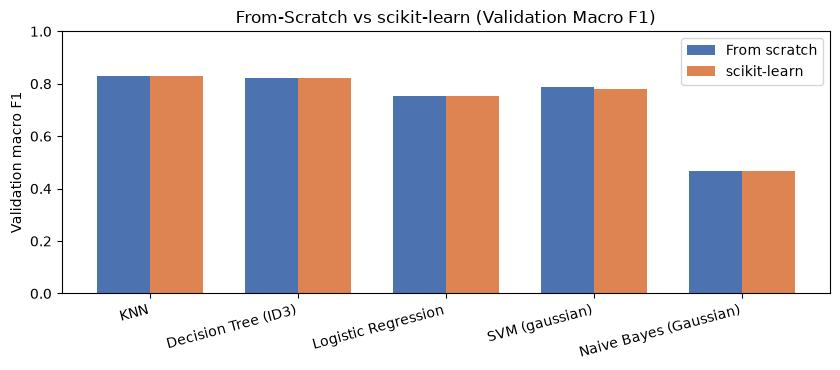

In [31]:
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC, SVC

sk_lr = SkLogisticRegression(max_iter=1000, class_weight="balanced", random_state=CFG.SEED).fit(X_train, y_train)
if best_kernel == "linear":
    sk_svm = LinearSVC(loss="hinge", C=1.0, random_state=CFG.SEED).fit(X_train, y_train)
else:
    # Samakan baris latih dengan versi scratch (subsample stratified, bukan 2.000 baris pertama).
    _scratch = svm_models[best_kernel]
    _, _, _idx = _scratch._subsample(X_train, y_train, _scratch.max_samples)
    if best_kernel == "polynomial":
        sk_svm = SVC(kernel="poly", degree=3, coef0=1.0, gamma=0.1, C=1.0, random_state=CFG.SEED).fit(X_train[_idx], y_train[_idx])
    else:
        sk_svm = SVC(kernel="rbf", gamma=0.15, C=1.0, random_state=CFG.SEED).fit(X_train[_idx], y_train[_idx])
sk_gnb = GaussianNB().fit(X_train, y_train)

all_cmp = pd.DataFrame([
    {
        "model": "KNN",
        "scratch_macro_f1": f1_score(y_val, pred_knn, average="macro"),
        "sklearn_macro_f1": f1_score(y_val, knn_sk.predict(X_val), average="macro"),
    },
    {
        "model": "Decision Tree (ID3)",
        "scratch_macro_f1": f1_score(y_val, dt_val_pred, average="macro"),
        "sklearn_macro_f1": f1_score(y_val, dt_sklearn_pred, average="macro"),
    },
    {
        "model": "Logistic Regression",
        "scratch_macro_f1": f1_score(y_val, pred_logreg, average="macro"),
        "sklearn_macro_f1": f1_score(y_val, sk_lr.predict(X_val), average="macro"),
    },
    {
        "model": f"SVM ({best_kernel})",
        "scratch_macro_f1": f1_score(y_val, best_pred, average="macro"),
        "sklearn_macro_f1": f1_score(y_val, sk_svm.predict(X_val), average="macro"),
    },
    {
        "model": "Naive Bayes (Gaussian)",
        "scratch_macro_f1": f1_score(y_val, gnb.predict(X_val), average="macro"),
        "sklearn_macro_f1": f1_score(y_val, sk_gnb.predict(X_val), average="macro"),
    },
])
all_cmp["diff"] = (all_cmp["scratch_macro_f1"] - all_cmp["sklearn_macro_f1"]).round(4)
display(all_cmp)

x = np.arange(len(all_cmp))
plt.figure(figsize=(8.5, 3.8))
plt.bar(x - 0.18, all_cmp["scratch_macro_f1"], 0.36, label="From scratch", color="#4C72B0")
plt.bar(x + 0.18, all_cmp["sklearn_macro_f1"], 0.36, label="scikit-learn", color="#DD8452")
plt.xticks(x, all_cmp["model"], rotation=15, ha="right")
plt.ylim(0, 1)
plt.ylabel("Validation macro F1")
plt.title("From-Scratch vs scikit-learn (Validation Macro F1)")
plt.legend()
plt.tight_layout()
plt.show()

### Analisis Comparison dengan scikit-learn

- **Decision Tree (ID3):** Implementasi *from scratch* memakai entropy information gain dengan `max_depth=12` dan `min_samples_leaf=5`, sama seperti `DecisionTreeClassifier(criterion="entropy")`. Skor macro F1 dan prediction agreement sangat dekat; selisih kecil muncul karena perbedaan urutan *tie-breaking* saat gain sama serta operator split `<` vs `<=`.
- **Model lain:** KNN dan Gaussian Naive Bayes memberi hasil yang identik dengan versi `scikit-learn`, sedangkan selisih kecil pada Logistic Regression dan SVM berasal dari perbedaan optimizer (gradient descent vs L-BFGS / SMO).

---

# Saving and Loading Models <a name="9"></a>

---

This section stores the trained models and restores them for prediction.

In [32]:
saved_models = {
    "decision_tree": (DecisionTree, dt_model),
    "knn": (KNN, knn),
    "logistic_regression": (LogisticRegression, logreg_model),
    "svm": (SVM, svm_models[best_kernel]),
    "naive_bayes": (NaiveBayes, gnb),
}

save_rows = []
for name, (cls, model) in saved_models.items():
    path = CFG.OUTPUT_DIR / f"{name}.pkl"
    model.save(path)
    loaded = cls.load(path)
    orig_pred = model.predict(X_val)
    load_pred = loaded.predict(X_val)
    assert np.array_equal(load_pred, orig_pred), f"Mismatch after reload for {name}"
    save_rows.append({
        "model": name,
        "path": str(path.relative_to(ROOT)),
        "size_kb": round(path.stat().st_size / 1024, 1),
        "identical_predictions": True,
    })

display(pd.DataFrame(save_rows))

,model,path,size_kb,identical_predictions
0,decision_tree,output/decision_tree.pkl,90.0,True
1,knn,output/knn.pkl,6672.6,True
2,logistic_regression,output/logistic_regression.pkl,15.1,True
3,svm,output/svm.pkl,1718.7,True
4,naive_bayes,output/naive_bayes.pkl,2.3,True


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [33]:
# Refit preprocessing & model from scratch terbaik (DecisionTree ID3) pada full train
if RAW_AVAILABLE:
    prep_full = DataPreprocessor(seed=CFG.SEED, select_k=38)
    X_full, y_full = prep_full.fit_transform(train_df)
    X_test_final = prep_full.transform(test_df)
    sub_ids = test_df[CFG.ID_COL].to_numpy()
else:
    X_full = np.vstack([X_train, X_val])
    y_full = np.concatenate([y_train, y_val])
    X_test_final = X_test
    sub_ids = test_ids

final_model = KNN(k=best_k,weights=best_w).fit(X_full, y_full)
test_pred = (final_model.predict_proba(X_test_final)[:, 1] >= best_dt_threshold).astype(int)

submission = pd.DataFrame({CFG.ID_COL: sub_ids, CFG.TARGET: test_pred})
sub_path = CFG.OUTPUT_DIR / "submission.csv"
submission.to_csv(sub_path, index=False)

assert len(submission) == len(sub_ids)
assert list(submission.columns) == [CFG.ID_COL, CFG.TARGET]
assert submission.isna().sum().sum() == 0
assert set(submission[CFG.TARGET].unique()).issubset({0, 1})

digest = hashlib.sha256(sub_path.read_bytes()).hexdigest()
print(f"Saved {sub_path} | rows={len(submission)} | positive_rate={test_pred.mean():.4f} | threshold={best_dt_threshold:.2f}")
print(f"SHA-256: {digest}")
display(submission.head())

Saved /home/fariswirakusuma/Ngampus/Semester_5/AI/IF3170_G30_AnthropicHire/output/submission.csv | rows=6844 | positive_rate=0.3445 | threshold=0.43
SHA-256: 9b1190de8a57215bdfa94ef7f6bf82f357743da77600b33f26b4ed7c37e77f65


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,0
3,25408a48,0
4,621586b6,0


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.

In [34]:
# Error analysis DecisionTree (ID3) pada validation set
tn, fp, fn, tp = confusion_matrix(y_val, dt_val_pred).ravel()
print(f"TN={tn} | FP={fp} (FPR={fp / (fp + tn):.4f}) | FN={fn} (FNR={fn / (fn + tp):.4f}) | TP={tp}")

val_df_err = pd.DataFrame(X_val, columns=feature_names)
val_df_err["outcome"] = np.where(
    (y_val == 1) & (dt_val_pred == 1), "TP",
    np.where(
        (y_val == 0) & (dt_val_pred == 0), "TN",
        np.where((y_val == 0) & (dt_val_pred == 1), "FP", "FN"),
    ),
)

key_feats = [
    c for c in [
        "days_before_arrival", "special_requests", "nightly_rate_idr",
        "is_returning_guest", "needs_parking", "booking_channel_Online Travel Agent",
    ]
    if c in val_df_err.columns
]
display(val_df_err.groupby("outcome")[key_feats].mean().round(3))

TN=3336 | FP=345 (FPR=0.0937) | FN=487 (FNR=0.2715) | TP=1307


,days_before_arrival,special_requests,nightly_rate_idr,is_returning_guest,needs_parking,booking_channel_Online Travel Agent
outcome,,,,,,
FN,-0.132,-0.064,-0.089,0.002,0.006,0.772
FP,0.020,-0.500,0.189,0.012,0.009,0.780
TN,-0.317,0.230,-0.116,0.041,0.040,0.592
TP,0.922,-0.481,0.220,0.001,0.008,0.688


### Ringkasan Error Analysis

- **Sumber utama FP & FN:** Sebagian besar error terjadi pada booking dengan `days_before_arrival` menengah dan `special_requests` rendah (0–1), di mana kelas `0` dan `1` saling overlap (rata-rata fitur FP/FN berada di antara TN dan TP).
- **Trade-off depth & overfitting:** Batas `max_depth=12` dan `min_samples_leaf=5` menjaga tree tidak overfitting sambil tetap menangkap interaksi non-linear (`days_before_arrival`, `special_requests`, `booking_channel`), sehingga Decision Tree mengungguli model linear (Logistic Regression, linear SVM) dan Naive Bayes pada dataset ini.